# 10 · Test evaluation and technical validation

All design decisions (architecture, hybrid, window, regularisation) were made with cross-validation in notebooks 07–09. Here the chosen models are trained on all 100 training engines and evaluated **once** on the official FD001 test set, the same protocol as Phase 1 notebook 05, so the numbers are directly comparable.

Validation steps:

1. **Seeds.** Every network is trained with 3 random seeds; we report each seed and their average (a seed ensemble).
2. **Uncertainty.** 95% bootstrap confidence intervals over the 100 test engines.
3. **Significance.** A paired Wilcoxon signed-rank test on per-engine errors against Phase 1's XGBoost.
4. **Error by degradation stage** (the brief's requirement), and the Phase 1 weak spots.
5. **What the network looks at:** gradient saliency over sensors and time.

In [1]:
import sys
from pathlib import Path

REPO = "https://github.com/WhiteHacker000/Remaining-Useful-Life-Prediction-for-Industrial-Engines.git"

# On Google Colab only the notebook is opened, so clone the repository to get src/ and the data
if "google.colab" in sys.modules and not Path("../src").exists():
    import os, subprocess
    if not Path("/content/rul").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/rul"], check=True)
    os.chdir("/content/rul/notebooks")

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json
import torch
from src.config import RUL_CAP, RESULTS_DIR, SENSOR_INFO, USEFUL_SENSORS
from src.data import load_cmapss, add_train_rul, add_test_rul
from src.evaluation import summarize, bootstrap_rmse, errors_by_stage, rmse, STAGES
from src.sequences import SequenceBuilder
from src.training import TrainConfig, run_final, _build
from src.dl_models import make_dl_model
from src.validation import last_rows as last, paired_wilcoxon, gradient_saliency
from src.plotting import set_style, save, BLUE, ORANGE, GREEN, GREY, INK, AQUA, VIOLET

set_style()
train, test, rul = load_cmapss("FD001")
train, test = add_train_rul(train), add_test_rul(test, rul)
DL = RESULTS_DIR / "dl"
hyb = {e: json.loads((DL / f"cv_hybrid_{e}_w30.json").read_text()) for e in ["lstm", "tcn", "transformer"]}
seq = {e: json.loads((DL / f"cv_{e}_w30.json").read_text()) for e in ["lstm", "tcn", "transformer"]}
enc = min(hyb, key=lambda e: hyb[e]["cv_rmse"])
NAMES = {"lstm": "LSTM", "tcn": "TCN", "transformer": "Transformer"}
print("hybrid encoder chosen by CV:", NAMES[enc])

hybrid encoder chosen by CV: LSTM


## 1. Final training

Each network is retrained on the 100 training engines (90 for fitting, 10 held out for validation) with seeds 0, 1 and 2, and predicts every test cycle. The three sequence models use the default configuration of notebook 07; the hybrid uses the configuration chosen by cross-validation in notebook 09 (a fixed 60 epochs instead of early stopping). Phase 1's tuned XGBoost is retrained with the hyperparameters from notebook 04, so all models are scored on exactly the same rows. Trained weights are saved in `outputs/models/`.

In [2]:
RETRAIN = False
cfg = TrainConfig(window=30)                                           # default configuration (notebook 07)
final_cfg = TrainConfig(window=30, early_stopping=False)    # 60 epochs, chosen by CV in notebook 09
runs = {"lstm": cfg, "tcn": cfg, "transformer": cfg, f"hybrid-{enc}": final_cfg}
final = {}
for name, c in runs.items():
    key = f"test_{name.replace('-', '_')}_w30" + ("_60ep" if c is final_cfg else "")
    summary, pred = run_final(key, name, train, test, c, retrain=RETRAIN)
    final[name] = pred
    print(f"{name:20s} seeds {[s['seed'] for s in summary['seeds']]}   ({summary['minutes']} min)")

# Phase 1 XGBoost on the same test rows. XGBoost and PyTorch must not share a process on
# macOS (see src/__init__.py), so its predictions come from a separate script.
import subprocess
xgb_file = RESULTS_DIR / "xgb_test_predictions.csv"
if not xgb_file.exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "xgb_test_predictions.py")], check=True)
xgb_pred = pd.read_csv(xgb_file)

lstm                 seeds [0, 1, 2]   (1.91 min)
tcn                  seeds [0, 1, 2]   (1.17 min)
transformer          seeds [0, 1, 2]   (2.49 min)
hybrid-lstm          seeds [0, 1, 2]   (4.65 min)


## 2. Official benchmark: last observed cycle

One prediction per test engine at its last observed cycle, scored against the true RUL from `RUL_FD001.txt`, exactly as in Phase 1.

In [3]:
base = last(final[f"hybrid-{enc}"])[["unit", "cycle", "true_rul"]]
cols = {"XGBoost, engineered (Phase 1)": last(xgb_pred)["pred_xgb"].to_numpy()}
for name in ["lstm", "tcn", "transformer", f"hybrid-{enc}"]:
    label = f"Hybrid ({NAMES[enc]} + features)" if name.startswith("hybrid") else f"{NAMES[name]} (sensor sequence)"
    cols[label] = last(final[name])["pred"].to_numpy()
    seed_cols = [c for c in final[name] if c.startswith("pred_seed")]
    cols[label + " seeds"] = [rmse(base["true_rul"], last(final[name])[c]) for c in seed_cols]

y = base["true_rul"].to_numpy()
rows = []
for label, p in cols.items():
    if label.endswith(" seeds"):
        continue
    lo, hi = bootstrap_rmse(y, p)
    s = cols.get(label + " seeds")
    rows.append({"model": label, **summarize(y, p), "RMSE 95% CI": f"{lo:.1f} - {hi:.1f}",
                 "single seeds (RMSE)": "-" if s is None else ", ".join(f"{v:.2f}" for v in s)})
bench = pd.DataFrame(rows).set_index("model")
bench.to_csv(DL / "test_benchmark_dl.csv")
bench.round(2)

,RMSE,MAE,Score,RMSE 95% CI,single seeds (RMSE)
model,,,,,
"XGBoost, engineered (Phase 1)",10.75,8.09,161.11,9.1 - 12.4,-
LSTM (sensor sequence),15.52,11.63,462.59,13.0 - 18.0,"15.66, 15.88, 16.35"
TCN (sensor sequence),14.72,11.21,322.32,12.6 - 16.7,"15.70, 14.75, 15.15"
Transformer (sensor sequence),15.03,11.17,366.95,12.7 - 17.3,"16.64, 15.69, 15.25"
Hybrid (LSTM + features),11.02,8.02,166.41,9.3 - 12.7,"11.68, 11.05, 11.39"


- **The hybrid scores RMSE 11.02** (95% CI 9.3–12.7) on the official benchmark, essentially level with Phase 1's XGBoost (10.75, CI 9.1–12.4). Its MAE is slightly lower (8.02 vs 8.09) and its NASA score slightly higher (166 vs 161). The three seeds give 11.05 to 11.68, and averaging them (the reported model) is better than any single seed.
- **The sequence-only networks score 14.7 to 15.5.** That is 3 to 3.5 cycles better than XGBoost on raw single-cycle sensors (18.19), but 4 to 5 cycles worse than the engineered features. This is the same ranking as cross-validation, so the CV protocol transferred faithfully to the test set.
- Seed-to-seed variation for the networks (about ±0.5 to 0.7 cycles) is of the same size as the differences between the best models. That is why the next section tests significance rather than comparing single numbers.

## 3. Is the difference significant?

Bootstrap intervals of two models overlap easily even when one model is consistently better, because they ignore that both models are scored on the **same** engines. A **paired** test compares the two models engine by engine. We use the Wilcoxon signed-rank test on the per-engine absolute errors, which does not assume normally distributed errors (with 100 engines and some large errors, normality is doubtful).

$H_0$: the median difference in absolute error between the two models is zero.

In [4]:
tests = {}
for label, p in cols.items():
    if label.endswith(" seeds") or label.startswith("XGBoost"):
        continue
    tests[label] = paired_wilcoxon(y, p, cols["XGBoost, engineered (Phase 1)"])
sig = pd.DataFrame(tests).T.rename(columns={"mean |error| A": "mean |error| model", "mean |error| B": "mean |error| XGBoost",
                                            "engines where A is better": "engines where model is better"})
sig.index.name = "model vs XGBoost"
sig.to_csv(DL / "test_significance.csv")
sig.round(4)

,mean |error| model,mean |error| XGBoost,engines where model is better,statistic,p-value
model vs XGBoost,,,,,
LSTM (sensor sequence),11.6260,8.0853,33.0,1466.0,0.0003
TCN (sensor sequence),11.2131,8.0853,38.0,1599.0,0.0015
Transformer (sensor sequence),11.1749,8.0853,40.0,1530.0,0.0006
Hybrid (LSTM + features),8.0191,8.0853,51.0,2488.0,0.8988


- **Each sequence-only network is significantly worse than XGBoost** (p ≤ 0.0015); they are better on only 33 to 40 of the 100 engines.
- **The hybrid and XGBoost are statistically indistinguishable** (p = 0.90). The hybrid is better on 51 engines and worse on 49. The two models' last-cycle errors are also highly correlated (r = 0.86): the engines that are hard for one are hard for the other.

So on the official benchmark, the honest conclusion is that the hybrid **matches** the engineered-feature model; it does not beat it.

## 4. Error by degradation stage

As in Phase 1, every test cycle is scored (13,096 points), split into early (RUL > 125), mid (50–125) and late (≤ 50) stages. Errors are measured against the capped target (for mid and late stages this equals the true RUL); positive bias means a late, risky prediction.

n   RMSE    MAE  \
model             stage                                       
XGBoost (Phase 1) early (RUL > 125)      7952   6.44   4.23   
                  mid (50 < RUL <= 125)  4258  12.44   9.60   
                  late (RUL <= 50)        886   5.70   4.23   
LSTM alone        early (RUL > 125)      7952   8.47   5.73   
                  mid (50 < RUL <= 125)  4258  17.36  13.41   
                  late (RUL <= 50)        886  12.75   8.09   
Hybrid            early (RUL > 125)      7952   5.95   3.92   
                  mid (50 < RUL <= 125)  4258  12.33   9.21   
                  late (RUL <= 50)        886   5.37   3.97   

                                         mean error (pred - true)  
model             stage                                            
XGBoost (Phase 1) early (RUL > 125)                         -2.69  
                  mid (50 < RUL <= 125)                      2.65  
                  late (RUL <= 50)                           1.95  
LSTM alone        early (RUL > 125)                         -5.71  
                  mid (50 < RUL <= 125)                      5.31  
                  late (RUL <= 50)                           6.34  
Hybrid            early (RUL > 125)                         -3.75  
                  mid (50 < RUL <= 125)                      2.88  
                  late (RUL <= 50)                           2.91

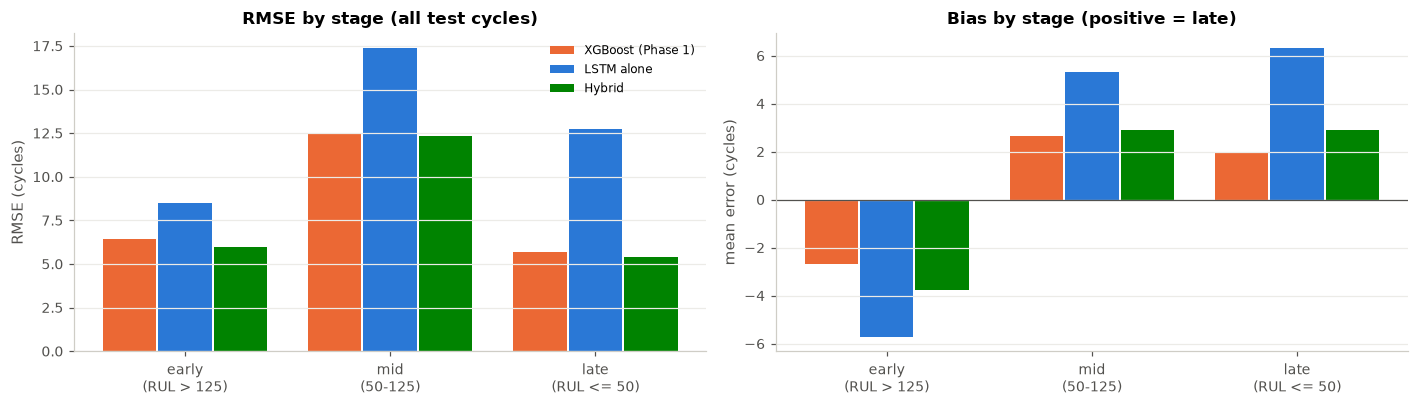

In [5]:
allrows = final[f"hybrid-{enc}"][["unit", "cycle", "true_rul"]].merge(xgb_pred, on=["unit", "cycle"])
for name in ["lstm", "tcn", "transformer", f"hybrid-{enc}"]:
    allrows[name] = final[name]["pred"].to_numpy()
true = allrows["true_rul"].to_numpy()
capped_true = np.minimum(true, RUL_CAP)
models = {"XGBoost (Phase 1)": "pred_xgb", f"{NAMES[enc]} alone": enc, f"Hybrid": f"hybrid-{enc}"}
stage = pd.concat({k: errors_by_stage(capped_true, allrows[c].to_numpy(), stage_rul=true) for k, c in models.items()},
                  names=["model"])
stage.to_csv(DL / "test_error_by_stage_dl.csv")
display(stage.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(3)
for k, (lab, color) in enumerate(zip(models, [ORANGE, BLUE, GREEN])):
    t = stage.loc[lab]
    axes[0].bar(x + (k - 1) * 0.27, t["RMSE"], 0.26, color=color, label=lab)
    axes[1].bar(x + (k - 1) * 0.27, t["mean error (pred - true)"], 0.26, color=color, label=lab)
for ax, title, yl in [(axes[0], "RMSE by stage (all test cycles)", "RMSE (cycles)"),
                      (axes[1], "Bias by stage (positive = late)", "mean error (cycles)")]:
    ax.set_xticks(x, ["early\n(RUL > 125)", "mid\n(50-125)", "late\n(RUL <= 50)"])
    ax.set(title=title, ylabel=yl)
    ax.grid(axis="x", visible=False)
axes[1].axhline(0, color=INK, lw=0.8)
axes[0].legend(fontsize=8)
fig.tight_layout()
save(fig, "10_error_by_stage")
plt.show()

Over **all 13,096 test cycles**, the hybrid has a lower error than XGBoost in **every stage**:

| Stage | XGBoost | Hybrid |
|---|---|---|
| early (RUL > 125) | 6.44 | **5.95** |
| mid (50–125) | 12.44 | **12.33** |
| late (≤ 50) | 5.70 | **5.37** |

Over all cycles that is an RMSE of 8.54 for the hybrid against 8.81 for XGBoost (3% lower). The margins are small, but they hold across the whole life, not only at the last cycle. The hybrid's bias is close to XGBoost's in the mid and late stages (+2.9 vs +2.7 and +2.9 vs +2.0 cycles). The LSTM on its own is clearly worse in every stage, especially near failure (12.75 vs 5.70), and is biased late (+6.3 cycles), the dangerous direction.

### The Phase 1 weak spots, on the test set

In [6]:
obs = test.groupby("unit")["cycle"].max()
life = obs + rul                                         # true lifetime of each test engine
L = base.assign(xgb=cols["XGBoost, engineered (Phase 1)"], hybrid=cols[f"Hybrid ({NAMES[enc]} + features)"],
                seq=cols[f"{NAMES[enc]} (sensor sequence)"])
L["obs"] = L["unit"].map(obs); L["life"] = L["unit"].map(life)
groups = {"short history (< 60 cycles observed)": L["obs"] < 60,
          "fast degrader (lifetime < 160)": L["life"] < 160,
          "near failure (true RUL <= 50)": L["true_rul"] <= 50,
          "all engines": L["true_rul"] >= 0}
spots = pd.DataFrame({g: {"engines": int(m.sum()),
                          "MAE XGBoost": np.abs(L.loc[m, "xgb"] - L.loc[m, "true_rul"]).mean(),
                          f"MAE {NAMES[enc]} alone": np.abs(L.loc[m, "seq"] - L.loc[m, "true_rul"]).mean(),
                          "MAE hybrid": np.abs(L.loc[m, "hybrid"] - L.loc[m, "true_rul"]).mean()}
                      for g, m in groups.items()}).T
spots.round(2)

,engines,MAE XGBoost,MAE LSTM alone,MAE hybrid
short history (< 60 cycles observed),12.0,10.71,10.44,10.35
fast degrader (lifetime < 160),13.0,10.46,12.49,10.50
near failure (true RUL <= 50),33.0,3.38,4.39,2.93
all engines,100.0,8.09,11.63,8.02


- **Near failure** (33 engines with true RUL ≤ 50): the hybrid has the lowest error, MAE **2.93** against 3.38 for XGBoost and 4.39 for the LSTM alone.
- **Short histories** (12 engines with fewer than 60 observed cycles): small gain, 10.35 vs 10.71.
- **Fast degraders** (13 engines that fail before cycle 160): no change (10.50 vs 10.46). As in cross-validation, both models use the engine's age, so an engine that wears out unusually fast still looks "too young to fail". This weak spot remains open.

## 5. Predictions along an engine's life

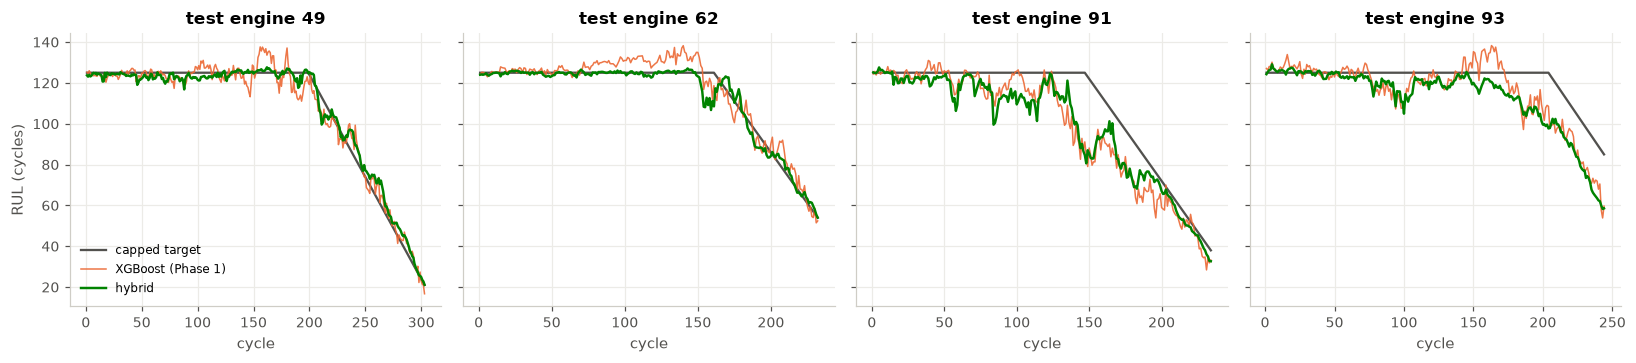

In [7]:
longest = obs.sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, u in zip(axes, sorted(longest)):
    m = allrows["unit"] == u
    c = allrows.loc[m, "cycle"]
    ax.plot(c, np.minimum(allrows.loc[m, "true_rul"], RUL_CAP), color=INK, lw=1.5, label="capped target")
    ax.plot(c, allrows.loc[m, "pred_xgb"], color=ORANGE, lw=1, alpha=0.9, label="XGBoost (Phase 1)")
    ax.plot(c, allrows.loc[m, f"hybrid-{enc}"], color=GREEN, lw=1.6, label="hybrid")
    ax.set(title=f"test engine {u}", xlabel="cycle")
axes[0].set_ylabel("RUL (cycles)")
axes[0].legend(fontsize=8)
fig.tight_layout()
save(fig, "10_test_trajectories")
plt.show()

## 6. What does the sequence branch look at?

**Gradient saliency:** for each test window, the absolute gradient of the predicted RUL with respect to every input value, $\left|\partial \hat y / \partial x_{s,\tau}\right|$, tells how much a small change in sensor $s$ at time step $\tau$ would move the prediction. Averaged over windows close to failure, it shows which sensors and which part of the window the network relies on.

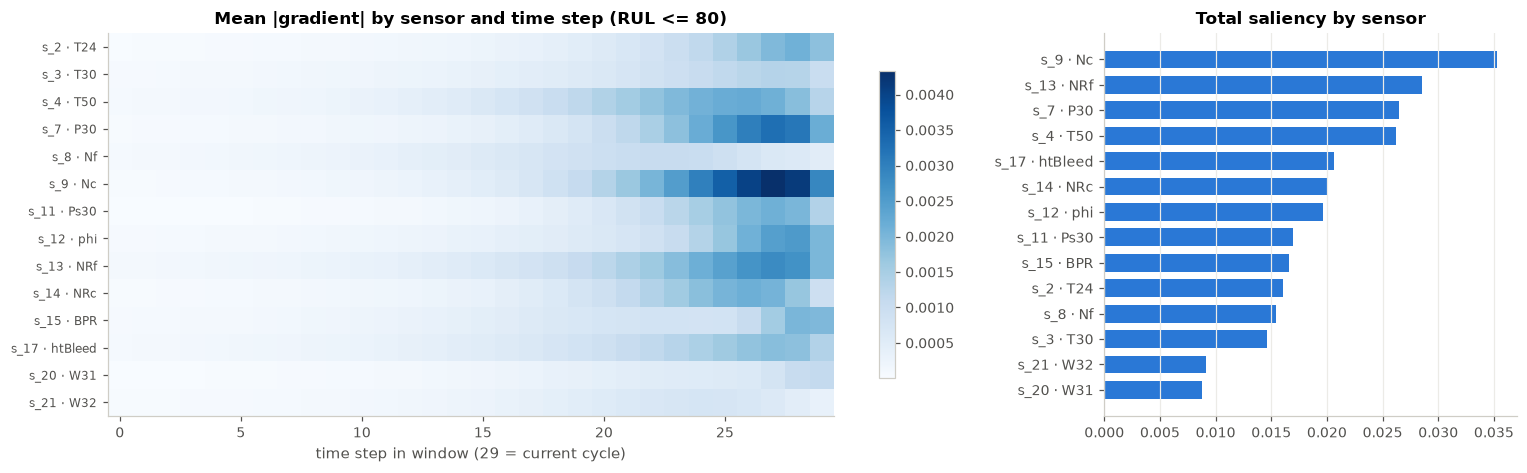

In [8]:
tr, va, te, sb = _build(train, test, cfg, True, 42)
net = make_dl_model(f"hybrid-{enc}", tr["x"].shape[2], cfg.window, n_feat=tr["f"].shape[1])
net.load_state_dict(torch.load(ROOT / "outputs" / "models" / f"test_hybrid_{enc}_w30_60ep_seed0.pt"))
net.eval()
pick = te["y"] <= 80
sal = gradient_saliency(net, te["x"][pick], te["f"][pick])[:, :-1].T     # (sensors, time), mask channel dropped

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
im = axes[0].imshow(sal, aspect="auto", cmap="Blues")
axes[0].set_yticks(range(14), [f"{s} · {SENSOR_INFO[s][0]}" for s in USEFUL_SENSORS], fontsize=8)
axes[0].set(title="Mean |gradient| by sensor and time step (RUL <= 80)", xlabel="time step in window (29 = current cycle)")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=0.8)
by_sensor = pd.Series(sal.sum(axis=1), index=[f"{s} · {SENSOR_INFO[s][0]}" for s in USEFUL_SENSORS]).sort_values()
axes[1].barh(by_sensor.index, by_sensor.values, color=BLUE, height=0.7)
axes[1].set(title="Total saliency by sensor")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "10_saliency")
plt.show()

- The network looks mostly at the **last 10 or so cycles** of the window, peaking 3–5 cycles before the current one. The oldest part of the window matters little, consistent with the window-length ablation: for the hybrid, more history adds little.
- The sensors it is most sensitive to are the **core speeds `s_9` (Nc) and `s_14` (NRc)**, the HPC outlet pressure `s_7` and the temperature `s_4`. Core speeds were the weakest sensors in Phase 1's ranking and had low weight in the PCA health index, because they behave differently across engines. The sequence branch uses exactly the signal that the hand-made features use least. That is direct evidence of the complementarity that motivated the hybrid.
- Saliency is a local sensitivity measure (Simonyan et al., 2014): it shows what the prediction reacts to, not a causal explanation.

## 7. Phase 1 versus Phase 2

In [9]:
summary = bench[["RMSE", "MAE", "Score", "RMSE 95% CI"]].copy()
p1 = pd.read_csv(RESULTS_DIR / "test_benchmark.csv")
raw = p1[(p1["model"] == "XGBoost") & (p1["variant"] == "raw / default")].iloc[0]
summary.loc["XGBoost, raw sensors (Phase 1)"] = [raw["RMSE"], raw["MAE"], raw["Score"], raw["RMSE 95% CI"]]
summary = summary.loc[["XGBoost, raw sensors (Phase 1)", "XGBoost, engineered (Phase 1)"] +
                      [i for i in bench.index if not i.startswith("XGBoost")]]
summary.to_csv(DL / "phase1_vs_phase2.csv")
summary

,RMSE,MAE,Score,RMSE 95% CI
model,,,,
"XGBoost, raw sensors (Phase 1)",18.185674,12.927941,962.878790,14.9 - 21.2
"XGBoost, engineered (Phase 1)",10.754107,8.085269,161.108943,9.1 - 12.4
LSTM (sensor sequence),15.524275,11.625985,462.592042,13.0 - 18.0
TCN (sensor sequence),14.720201,11.213058,322.315763,12.6 - 16.7
Transformer (sensor sequence),15.030747,11.174872,366.951070,12.7 - 17.3
Hybrid (LSTM + features),11.018628,8.019075,166.408155,9.3 - 12.7


## Summary of Phase 2

| Model (official test set) | RMSE | MAE | vs. XGBoost (Wilcoxon) |
|---|---|---|---|
| XGBoost, raw sensors (Phase 1) | 18.19 | 12.93 | – |
| LSTM / TCN / Transformer, raw sensor windows | 15.5 / 14.7 / 15.0 | 11.6 / 11.2 / 11.2 | significantly worse (p ≤ 0.002) |
| XGBoost, engineered features (Phase 1) | 10.75 | 8.09 | – |
| **Hybrid: LSTM + engineered features** | **11.02** | **8.02** | no significant difference (p = 0.90) |

**What we learned**

1. Sequence models learn real degradation patterns from raw sensors (much better than raw single-cycle features), but on 100 engines they **do not match carefully engineered degradation features**. The decisive information, each engine's distance from its own healthy baseline and its age, lies outside a fixed window.
2. The **hybrid** recovers the whole gap (15 → 11) by giving the network that context, beats both of its parts and simple averaging in cross-validation, and **matches** the best feature-based model on the official benchmark. Over all test cycles it has a slightly lower error in every degradation stage, and the lowest error near failure.
3. The engineered features are the backbone (ablation: +4.5 without them); the sequence branch adds a consistent but small gain and uses different sensors (core speeds) than the features do.
4. An unsolved weak spot: **fast-degrading engines** are still predicted about 10 cycles late by every model.